# Phase 3, part 1: portability and numerics

**Question this notebook answers.** Can the geodesign pipeline run on a region that is not Belauri? And how far can we trust the
numbers of the finite-volume solver, given that its numerical diffusion is larger than the physical diffusion?

Everything here is **synthetic** (emissions, winds, the second region). Real geography alone validates nothing.
Evidence lives in `results/phase3-convergence/`, `results/phase3-scheme/`, `docs/transfer.md` and `docs/numerical-methodology.md`.
Findings: T-023, F-025. Summary of all Phase 3 claims: `docs/phase3-findings.md`.

## What this shows / does not show

**Shows**
* The pipeline ran end to end on a second, unlike, synthetic region after config and asset changes. One loader function needed a role-name change.
* At the Belauri mesh (500 m), the effective diffusion K_eff is 2 to 11 times the nominal K in the EXP-015 stage-1 runs. Grid and time step set most of the diffusion.
* On one case with one wind, the 500 m field differs by about 5 % (relative L2 norm) from the 125 m field. The observed order is near 1.
* The `vanleer` flux-limited scheme is much less diffusive. It is nonlinear. So it can verify results, but it cannot replace the linear solver in design runs.

**Does not show**
* That the pipeline works on a real second municipality. Only one fake L-shaped region was tested.
* That sensor-design decisions are stable with mesh. That is EXP-015 stage 2. It is not run (see notebook 10).
* Anything about real air quality.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path("..").resolve()          # notebooks run with cwd = notebooks/
R = ROOT / "results"
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:.4g}")

def show(path, width=760):
    """Show a saved PNG from results/. Skips quietly if the file is missing."""
    p = Path(path)
    if p.exists():
        display(Image(filename=str(p), width=width))
    else:
        print("missing:", p.relative_to(ROOT))

def load(path):
    p = Path(path)
    if not p.exists():
        print("missing:", p.relative_to(ROOT)); return None
    return pd.read_csv(p)

## 1. Region roles and the second synthetic region

The pipeline reads raw files by **role**, not by country name. A role is a label such as `study`, `adm0_<ISO>`, `dem` or `osm_roads`.
Before Phase 3, the loader assumed the roles `adm0_NPL` and `adm0_IND`. Now the geodesign config can name them (`region.roles`).

`tests/test_transfer.py` builds an obviously fake region and runs the real pipeline on it (smoke settings, no mocks):
* L-shaped town, near 10 E and 33 S (UTM zone 32S, southern hemisphere),
* home country `ZZA`, neighbour `ZZB`,
* dense road grid in one arm, one road in the other arm, no facilities.

The test asserts the same output files and CSV column names as for Belauri. See `docs/transfer.md` for the full list of what stays Belauri-specific.

In [2]:
text = (ROOT / "tests" / "test_transfer.py").read_text().splitlines()
print("\n".join(text[:5]))            # the fixture docstring
print()
print(pd.DataFrame({
    "Region-independent": ["config, forward, inverse, attribution, design, experiments",
                           "geodesign after the geography is loaded"],
    "Supplied by the researcher": ["raw files per role + prepare config", "geodesign config: region block only"],
    "Still Belauri-specific": ["LOCAL_LAYERS (road, builtup, facility); mandatory external patch",
                               "output column names (e.g. in_nepal_adm0); tolerance LOCAL_ORIGIN_TOL = 0.06"],
}).to_string(index=False))

"""Transfer check: the geodesign pipeline runs on a second, UNLIKE synthetic region by changing only config + assets.
ALL data here is a SYNTHETIC fixture (obviously fake: L-shaped 'Lshape Town' at ~10 E / 33 S, home 'ZZA', neighbour 'ZZB', a
dense road grid in the east arm only, no facilities at all).  Real FiPy solves on the tiny smoke settings; no mocks.
Skipped without the optional geo extra (shapely / rasterio / pyproj)."""
from __future__ import annotations

                                        Region-independent          Supplied by the researcher                                                      Still Belauri-specific
config, forward, inverse, attribution, design, experiments raw files per role + prepare config            LOCAL_LAYERS (road, builtup, facility); mandatory external patch
                   geodesign after the geography is loaded geodesign config: region block only output column names (e.g. in_nepal_adm0); tolerance LOCAL_ORIGIN_TOL = 0.06


**Limits (from `docs/transfer.md`).** A region with no neighbour was tested only for `load_geography` and the candidate table, not end to end.
`geodesign_robust`, real data, network fetch and full-size budgets were not tested on the new region.

## 2. Numerical diffusion: a teaching demo (not the FiPy code)

An advection scheme smears a sharp feature even when the physical diffusion is zero. This smearing acts like extra diffusion.
For first-order upwind with an explicit step, the extra diffusion is `K_num = u dx (1 - C) / 2`.
Here `u` is wind speed in m/s, `dx` is cell size in m, and `C = u dt / dx` is the Courant number.
A backward-Euler (implicit) step gives `K_num = u dx (1 + C) / 2`.

**The code below is a 15-line teaching demo in numpy. It is not the FiPy solver and not the project's exponential scheme.**
"Implicit upwind" stands in for the time stepping of the FiPy exponential scheme at large cell Peclet number (there it reduces to upwind weights).
"Minmod" is a simple flux-limited second-order scheme, in the same family as `vanleer` but not identical.
Setting: periodic 1-D domain of 10 km, `dx` = 50 m, `u` = 1 m/s, `C` = 0.5, Gaussian of width 300 m moved by 4 km.

In [3]:
nx, dx, u, C, steps = 200, 50.0, 1.0, 0.5, 160          # steps*C*dx = 4000 m of travel
x = (np.arange(nx) + 0.5) * dx

def advect(phi, scheme, steps=steps):
    for _ in range(steps):
        if scheme == "upwind":                           # explicit, first order
            phi = phi - C * (phi - np.roll(phi, 1))
        elif scheme == "implicit upwind":                # backward Euler, first order
            M = (1 + C) * np.eye(nx) - C * np.roll(np.eye(nx), 1, axis=0)
            phi = np.linalg.solve(M, phi)
        else:                                            # explicit, minmod-limited slope (second order)
            d = np.diff(phi, append=phi[:1]); dm = np.roll(d, 1)
            slope = np.where(d * dm > 0, np.sign(d) * np.minimum(abs(d), abs(dm)), 0.0)
            face = phi + 0.5 * (1 - C) * slope           # value on the right face, upwind side
            phi = phi - C * (face - np.roll(face, 1))
    return phi

gauss = lambda x0, s: np.exp(-0.5 * ((x - x0) / s) ** 2)
phi0, exact = gauss(2000, 300), gauss(6000, 300)
var = lambda f: np.sum(f * (x - np.sum(f * x) / f.sum()) ** 2) / f.sum()
t, K_nominal = steps * C * dx / u, 1.0                   # s ; m^2/s (assumed physical K for the ratio)
rows, fields = [], {}
for s in ("upwind", "implicit upwind", "minmod"):
    f = advect(phi0, s); fields[s] = f
    Keff = (var(f) - var(phi0)) / (2 * t)
    rows.append({"scheme": s, "peak (exact = 1)": f.max(), "min value": f.min(),
                 "rel L2 error": np.linalg.norm(f - exact) / np.linalg.norm(exact),
                 "K_eff measured (m^2/s)": Keff, "K_eff / K (K = 1 m^2/s)": 1 + Keff / K_nominal})
pd.DataFrame(rows).set_index("scheme")

,peak (exact = 1),min value,rel L2 error,K_eff measured (m^2/s),K_eff / K (K = 1 m^2/s)
scheme,,,,,
upwind,0.6868,2.262e-31,0.2913,12.5,13.5
implicit upwind,0.4813,2.794e-14,0.5058,37.5,38.5
minmod,0.8929,1.174e-42,0.0678,1.396,2.396


theory K_num (m^2/s): upwind 12.5, implicit upwind 37.5


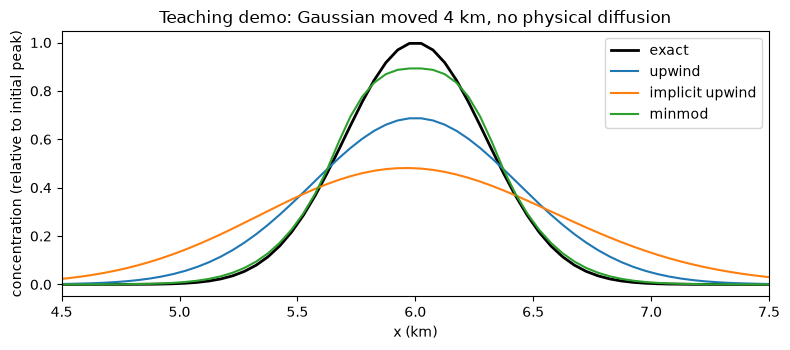

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(x / 1000, exact, "k", lw=2, label="exact")
for s, f in fields.items():
    ax.plot(x / 1000, f, label=s)
ax.set_xlim(4.5, 7.5); ax.set_xlabel("x (km)"); ax.set_ylabel("concentration (relative to initial peak)")
ax.set_title("Teaching demo: Gaussian moved 4 km, no physical diffusion"); ax.legend(); fig.tight_layout()
print("theory K_num (m^2/s): upwind %.1f, implicit upwind %.1f" % (u*dx*(1-C)/2, u*dx*(1+C)/2))

Read the table like this. The exact Gaussian keeps peak 1. Upwind and implicit upwind lose peak height and widen. The measured `K_eff` matches the theory above.
The implicit step diffuses more than the explicit step. The limited scheme keeps most of the peak and stays positive in this run.
In the real model the same effect makes K_eff/K between 2.2 and 10.9 in the stage-1 runs (see section 5). The ratio here is large because the assumed K is only 1 m^2/s.

## 3. Why a limited scheme is nonlinear

The inverse problem uses cached source responses and adds them (superposition). That is valid only for linear solvers.
A flux limiter chooses the slope from the data (here with min and sign tests). So the response to `a + b` is not the sum of the responses.
Test: advect two overlapping pulses together and apart, and compare.

In [5]:
a, b = gauss(2000, 250), 0.6 * gauss(2300, 250)
rows = []
for s in ("upwind", "implicit upwind", "minmod"):
    S = lambda f: advect(f, s, steps=40)
    rows.append({"scheme": s, "max |S(a+b) - S(a) - S(b)|": np.abs(S(a + b) - S(a) - S(b)).max()})
pd.DataFrame(rows).set_index("scheme")

,max |S(a+b) - S(a) - S(b)|
scheme,
upwind,2.776e-16
implicit upwind,1.665e-16
minmod,0.06702


The two linear schemes give differences at rounding level (about 1e-16). The limited scheme gives a clearly non-zero difference.
That is why `ResponseCache` refuses `vanleer` and why the project uses it only to verify fields (`docs/phase3-findings.md`, "Decisions").

## 4. The `vanleer` scheme in the real solver: `results/phase3-scheme/scheme_check.csv`

Produced by `scripts/scheme_check.py` (about 90 s). It compares `exponential`, `upwind` and `vanleer` against exact solutions
(periodic Gaussian) and against budget closure. `Keff_over_K` is `1 +` the excess second-moment growth divided by `2 K T`.

In [6]:
sc = load(R / "phase3-scheme" / "scheme_check.csv")
g = sc[(sc.study == "gauss_fixed") & sc.metric.isin(["rel_L2", "Keff_over_K", "min_value"])]
g.pivot_table(index=["metric", "scheme"], columns="dx_m", values="value").sort_index(axis=1, ascending=False)

dx_m                          500       250       125
metric      scheme                                   
Keff_over_K exponential     1.873     1.279     1.089
            upwind          2.632      1.83     1.426
            vanleer         1.039     1.001    0.9997
min_value   exponential 8.282e-07 1.122e-07 4.649e-08
            upwind      6.187e-06 6.787e-07  1.72e-07
            vanleer      3.17e-08 2.467e-08 3.006e-08
rel_L2      exponential    0.1524   0.05683   0.01936
            upwind         0.2334    0.1375   0.07701
            vanleer       0.04197  0.008006  0.002259

In [7]:
o = sc[(sc.study == "gauss_fixed") & (sc.metric == "order_L2")].pivot_table(index="scheme", columns="dx_m", values="value")
print("Observed order of the L2 error (dt fixed at 7.5 s; columns = finer dx in m):"); print(o)
m = sc[sc.metric == "max_rel_budget_residual"].groupby("scheme").value.max()
print("\nLargest relative mass-budget residual per scheme:"); print(m)

Observed order of the L2 error (dt fixed at 7.5 s; columns = finer dx in m):
dx_m           125    250
scheme                   
exponential  1.554  1.424
upwind      0.8367 0.7633
vanleer      1.825   2.39

Largest relative mass-budget residual per scheme:
scheme
exponential   4.006e-13
upwind        9.118e-14
vanleer       2.987e-13
Name: value, dtype: float64


**Reading.** On the periodic test, `vanleer` has K_eff/K close to 1 at every mesh, while upwind is 1.4 to 2.6 and the exponential scheme is 1.1 to 1.9.
The observed order of `vanleer` is 1.8 to 2.4. Upwind is below 1. The budget closes to rounding level for all schemes.
This is one test family (smooth Gaussian). A limited scheme is first order at extrema and for sharp fronts, so do not read "second order" as a general claim.

## 5. K_eff / K on the Belauri meshes

`results/phase3-convergence/` holds EXP-015 stage 1 (RUN-0028): one design case, one wind, same sources and physics at every mesh. Only mesh, time step and scheme change.
`keff_over_k` is the exponential-scheme formula `1 + numerical_diffusion_estimate(u, dx, dt, K)` and is **not** measured for `vanleer`.

In [8]:
runs = load(R / "phase3-convergence" / "stage1_runs.csv")
r = runs[(runs.scheme == "exponential") & runs.group.isna()][["res_m", "dt_s", "cells", "wall_s", "keff_over_k", "rel_budget_residual"]]
r.sort_values(["res_m", "dt_s"], ascending=[False, True]).reset_index(drop=True)

,res_m,dt_s,cells,wall_s,keff_over_k,rel_budget_residual
0,500,12.5,4290,32.94,6.019,6.432e-14
1,500,25,4290,16.71,6.343,7.683e-14
2,500,50,4290,8.16,6.992,3.287e-14
3,500,100,4290,4.15,8.289,1.432e-14
4,500,200,4290,2.28,10.88,1.273e-14
5,250,25,17160,56.22,3.515,4.259e-14
6,250,50,17160,28.11,4.164,2.016e-14
7,125,25,68640,272.7,2.248,2.524e-14


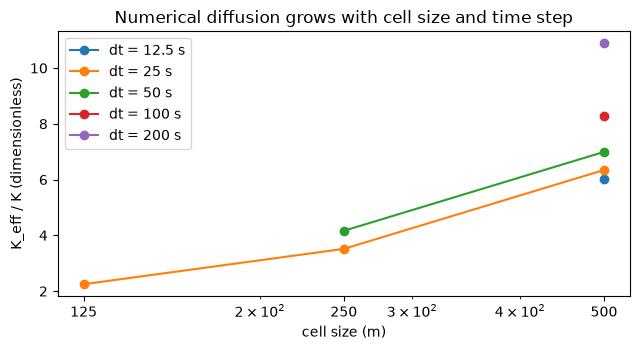

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for dt, grp in r.groupby("dt_s"):
    ax.plot(grp.res_m, grp.keff_over_k, "o-", label=f"dt = {dt:g} s")
ax.set_xscale("log"); ax.set_xticks([125, 250, 500]); ax.set_xticklabels(["125", "250", "500"])
ax.set_xlabel("cell size (m)"); ax.set_ylabel("K_eff / K (dimensionless)"); ax.legend()
ax.set_title("Numerical diffusion grows with cell size and time step"); fig.tight_layout()

Both a coarser mesh and a longer step raise K_eff. At 500 m and dt 25 s, K_eff/K is about 6.3. The saved figure from the run is below.

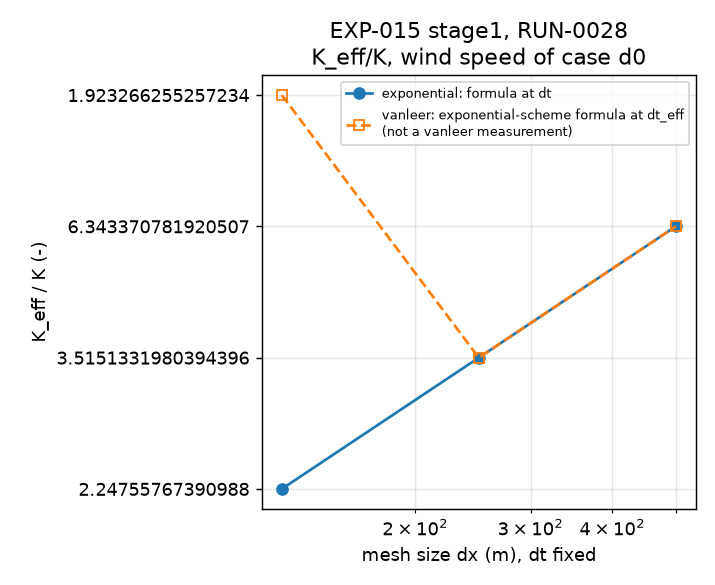

In [10]:
show(R / "phase3-convergence" / "figures" / "keff_vs_mesh.png", 560)

## 6. Observed order and the reference floor

No exact solution exists for the real case. So errors are measured against a fine "reference" field (125 m, dt 25 s).
Two references exist: `R_exp` (exponential scheme) and `R_vl` (`vanleer`). **They differ from each other.** The reference carries its own numerical error.
So a stated error is a **lower bound** of the true error, and an observed order depends on which reference is used (F-022 was corrected to F-025 for this reason).

In [11]:
s = load(R / "phase3-convergence" / "stage1_summary.csv")
base = s[(s.scheme == "exponential") & s.group.isna() & (s.dt_s == 25)][["res_m", "ref", "rel_L2"]]
print("Relative space-time L2 error of the exponential scheme at dt = 25 s (vs the stated reference):")
print(base.pivot(index="res_m", columns="ref", values="rel_L2").sort_index(ascending=False))
rv = s[(s.res_m == 125) & s.group.isna() & (s.scheme == "vanleer") & (s.ref == "R_exp")].rel_L2.iloc[0]
print(f"\nReference floor: the two 125 m references differ by {rv:.4f} (relative L2).")

Relative space-time L2 error of the exponential scheme at dt = 25 s (vs the stated reference):
ref     R_exp    R_vl
res_m                
500   0.05014 0.05528
250   0.01503 0.02131
125         0 0.00823

Reference floor: the two 125 m references differ by 0.0082 (relative L2).


In [12]:
o = load(R / "phase3-convergence" / "stage1_orders.csv")
o[o.study.isin(["A_space", "B_time"])].reset_index(drop=True)

,study,scheme,ref,levels,method,p,status
0,A_space,exponential,R_exp,500->250 m,L2 error ratio,1.738,ok
1,A_space,exponential,R_vl,500->250 m,L2 error ratio,1.375,ok
2,A_space,exponential,R_vl,250->125 m,L2 error ratio,1.372,ok
3,A_space,exponential,none,500/250/125 m,Richardson on time-mean study-mean,1.018,ok
4,A_space,vanleer,R_exp,500->250 m,L2 error ratio,0.7719,ok
5,A_space,vanleer,R_exp,250->125 m,L2 error ratio,0.05014,ok
6,A_space,vanleer,R_vl,500->250 m,L2 error ratio,1.496,ok
7,A_space,vanleer,none,500/250/125 m,Richardson on time-mean study-mean,-1.534,not converging (successive change grows)
8,B_time,exponential,self dt=12.5,200->100 s,L2 error ratio,0.8252,ok
9,B_time,exponential,self dt=12.5,100->50 s,L2 error ratio,1.142,ok


**Reading (F-025).** Against `R_exp` the space order is 1.74; against `R_vl` it is 1.38 (both levels). The Richardson estimate on the time-mean is 1.02.
The time order is 0.7 to 1.5 and tends to 1.0 for the finer steps. At dt 25 s the 500 m field has about 5 to 6 % space-time error. Mesh error dominates time-step error at 500 m.
The `vanleer` rows with order 0.05 or negative are an artefact of the reference floor: the 250 m and 125 m `vanleer` fields differ from `R_exp` by about 0.8 %, which is the gap between the two references. The Richardson estimate for `vanleer` is declared "not converging" in the table. Do not read these rows as an order.

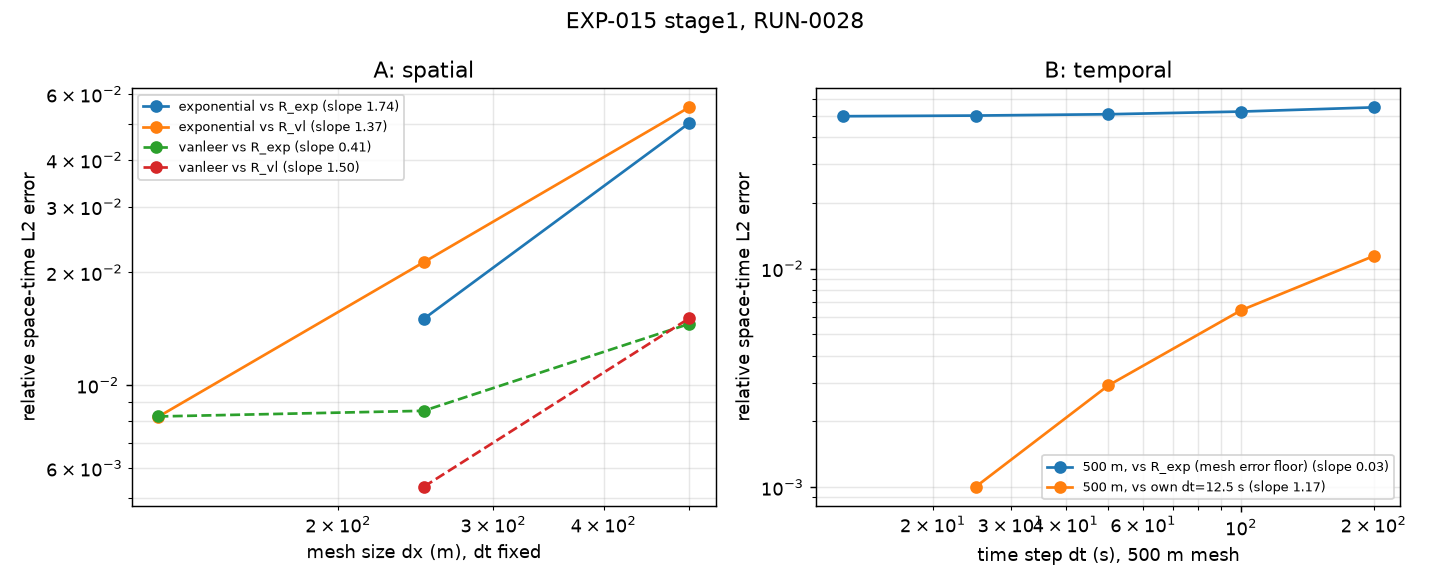

In [13]:
show(R / "phase3-convergence" / "figures" / "error_vs_dx_dt.png", 760)

**Source groups.** The external-patch fingerprint is the worst resolved (about 10 % at 500 m), road about 4 %.

In [14]:
f = s[s.group.notna()][["group", "res_m", "rel_L2"]]
f.pivot(index="group", columns="res_m", values="rel_L2")[[500.0, 250.0, 125.0]]

res_m,500,250,125
group,,,
bg,0.04013,0.01586,0
builtup,0.06405,0.01912,0
external_patch,0.09765,0.02907,0
road,0.03647,0.01106,0


## Limitations

* One case, one wind, one source draw. Intervals are not given because there is no replicate. Stated errors are lower bounds (reference floor).
* `K_eff/K` for the real runs is a formula, not a measurement, and is not defined for `vanleer`.
* The teaching demo is 1-D, periodic and uses an assumed K = 1 m^2/s. It illustrates the mechanism only.
* The second region is fake. It shows the code path transfers, not that results are meaningful.
* Whether sensor-design decisions change with mesh (EXP-015 stage 2) is **not** known.

Next: `08_phase3_population_design.ipynb`.